# Data visualization agent — walkthrough

Chat with a CSV file and get charts. The LLM picks a **typed chart tool** and its columns; Python draws the chart. No LLM-written code is executed. Runs **offline by default** (rule-based stand-in model: no API key, no cost). Set `PROVIDER = "gemini"` (free key) or `"openai"` for a real LLM.

In [1]:
PROVIDER = "offline"  # "gemini" | "openai" | "offline"

import os, json
from pathlib import Path
from dotenv import load_dotenv
from IPython.display import Image, display
load_dotenv()
os.environ["CHART_DIR"] = "charts"

from viz_agent import (TOOLS, STORE, configure, make_chart, describe_dataset, aggregate,
                       build_agent, get_llm, ask, final_answer, tool_calls, charts)
from viz_agent.cli import print_trace
configure(Path("..") / "data" if Path.cwd().name == "notebooks" else "data", "students.csv")
df = STORE.load()
print(df.shape)
df.head(3)

(400, 17)


,school,sex,age,address,Medu,Fedu,studytime,failures,internet,freetime,goout,Dalc,Walc,absences,G1,G2,G3
0,River Academy,M,15,urban,3,4,3,1,yes,3,4,1,3,8,13,11,10
1,North High,M,16,urban,4,3,2,1,yes,3,3,1,3,16,8,9,9
2,North High,M,15,urban,4,4,2,0,no,4,5,1,2,5,14,12,12


## 1. The tools — what the LLM sees
Name + docstring + typed arguments. The model can only *fill in* these arguments; it can't run arbitrary code.

In [2]:
for t in TOOLS:
    print(f"{t.name:17} args={list(t.args)}")

list_datasets     args=[]
describe_dataset  args=['file_name']
aggregate         args=['column', 'by', 'agg', 'file_name']
correlation       args=['x', 'y', 'file_name']
filter_rows       args=['column', 'op', 'value', 'file_name', 'limit']
make_chart        args=['kind', 'x', 'y', 'hue', 'agg', 'title', 'file_name']


## 2. Call a chart tool directly (no LLM)
It returns the PNG path, the numbers shown, and the equivalent pandas code.

{"values": {"no": 10.549, "yes": 10.951}, "n": {"no": 133, "yes": 267}}
import pandas as pd
import matplotlib.pyplot as plt

df = pd.read_csv('data/students.csv')
df.groupby('internet')['G3'].mean().plot(kind='bar')
plt.title('Average G3 by internet')
plt.savefig('bar-internet-G3-mean.png')


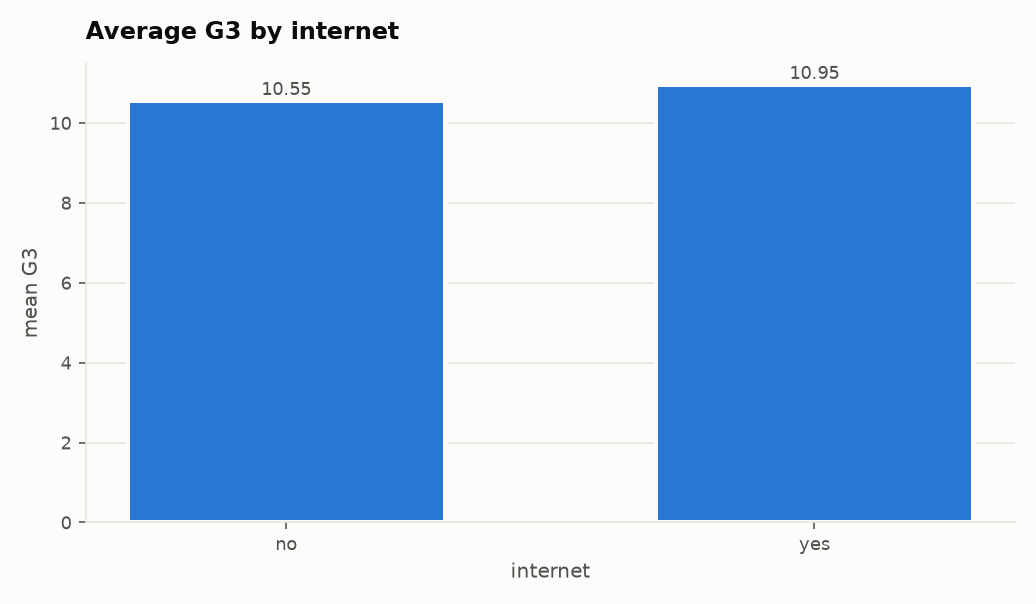

In [3]:
result = make_chart.invoke({"kind": "bar", "x": "internet", "y": "G3"})
print(json.dumps(result["summary"]))
print(result["code"])
display(Image(result["path"], width=520))

## 3. The lab's four tasks, asked in plain English

🤖 Number of rows by sex - F: 202, M: 198. Chart saved to charts/count-sex.png.


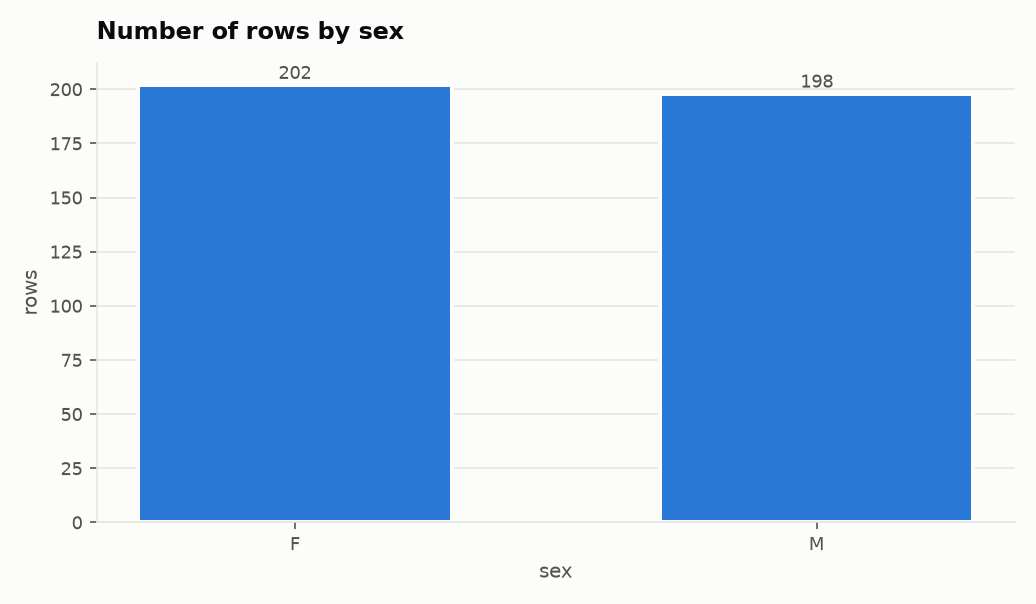

🤖 Average Walc by sex - F: 2.2 (50.4%), M: 2.17 (49.6%). Chart saved to charts/pie-sex-Walc-mean.png.


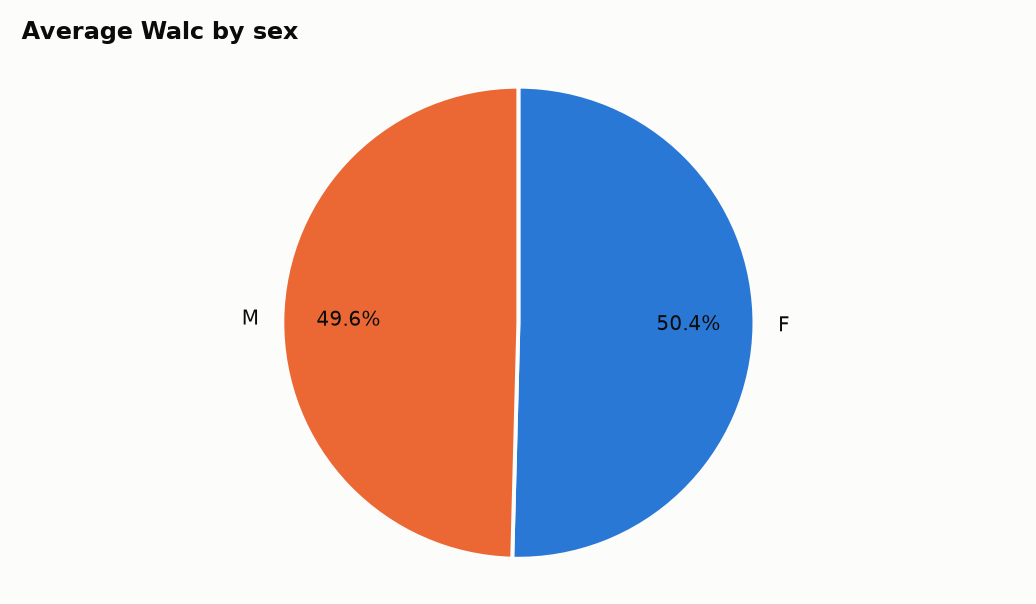

🤖 Distribution of G3 by freetime. Median G3 by freetime: 1: 10, 2: 10, 3: 11, 4: 11, 5: 11. Chart saved to charts/box-freetime-G3.png.


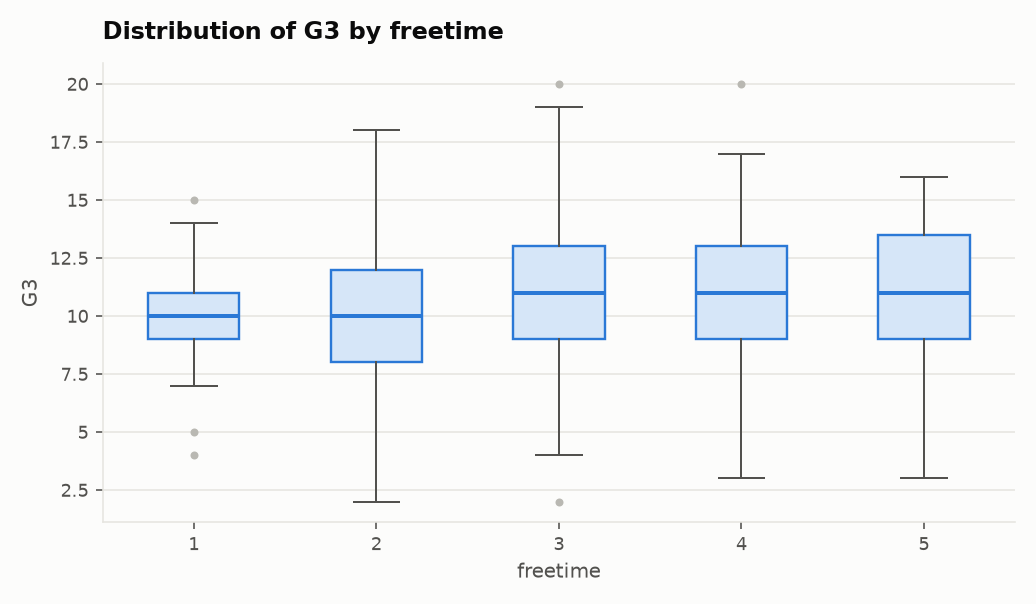

🤖 G3 vs Dalc: r = -0.151 (weak negative relationship). Average G3 goes from 11.08 at Dalc=1 to 9.2 at Dalc=5. Chart saved to charts/scatter-Dalc-G3.png. G3 vs Walc: r = -0.064 (no clear relationship). Average G3 goes from 11.13 at Walc=1 to 10.15 at Walc=5. Chart saved to charts/scatter-Walc-G3.png.


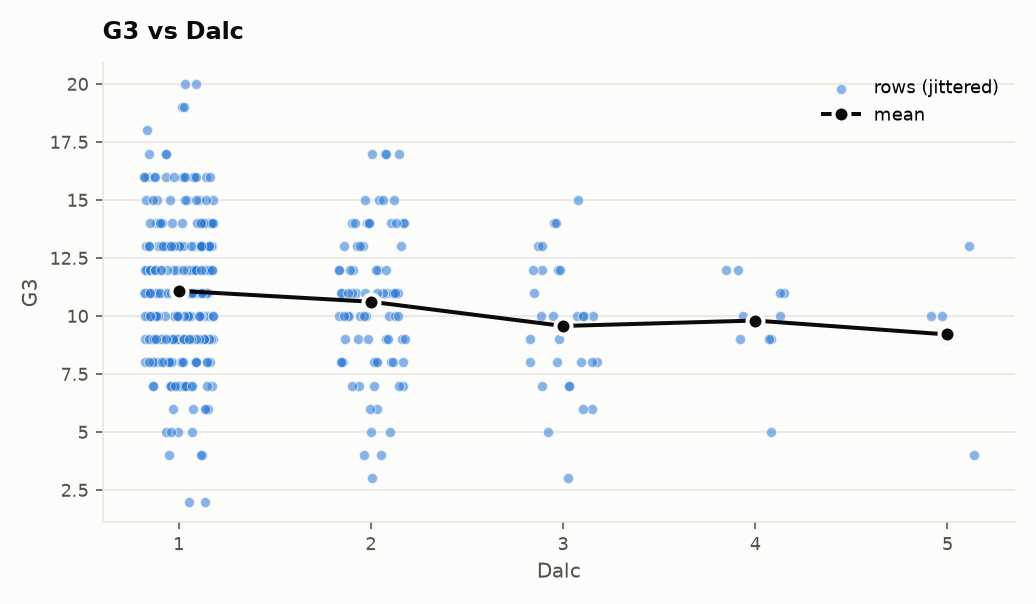

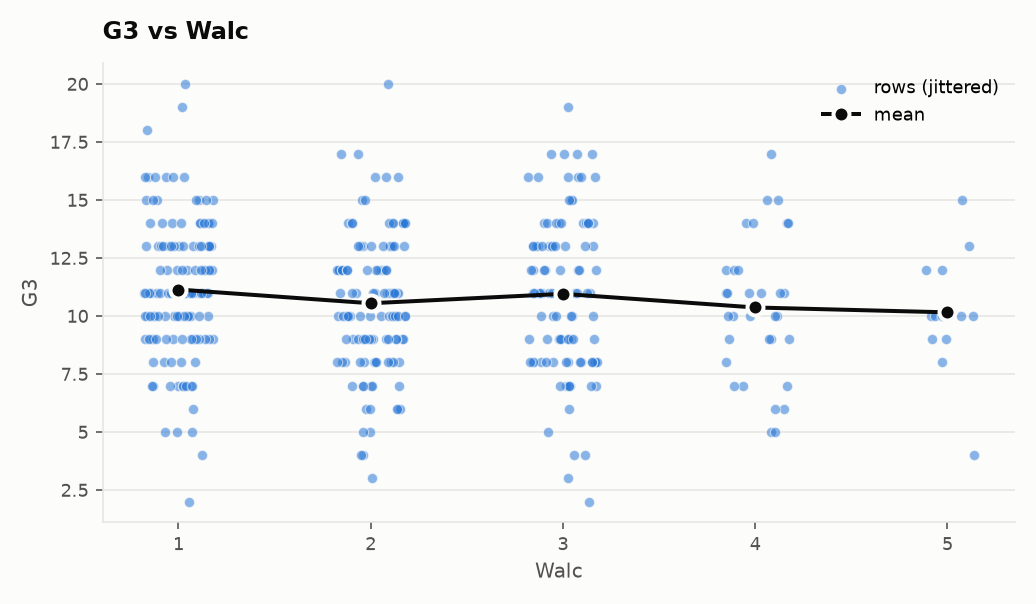

In [4]:
agent = build_agent(get_llm(PROVIDER))
LAB = ["Generate a bar chart to plot the gender count.",
       "Generate a pie chart to display average value of Walc for each Gender.",
       "Create box plots to analyze the relationship between 'freetime' and 'G3' across different levels of free time.",
       "Generate scatter plots to examine the correlation between 'Dalc' and 'G3', and between 'Walc' and 'G3'."]
for q in LAB:
    response = ask(agent, q)
    print("🤖", final_answer(response))
    for path in charts(response):
        display(Image(path, width=440))

## 4. Exercises
**Exercise 1** — mother's and father's education vs final grade (two charts from one question: the model makes **parallel tool calls**).

[1] Human       Generate scatter plots showing the relationship between 'Medu' (mother's education level) and 'G3' (final grade), and between 'Fedu' (father's education level) and 'G3'.
[2] AI → 2 tools  make_chart({'kind': 'scatter', 'x': 'Medu', 'y': 'G3', 'file_name': 'students.csv'})
[2] AI → 2 tools  make_chart({'kind': 'scatter', 'x': 'Fedu', 'y': 'G3', 'file_name': 'students.csv'})
[3] Tool        make_chart → 🖼  charts/scatter-Medu-G3.png
                {"pearson_r": 0.288, "n": 400, "mean_by_x": {"0": 8.444, "1": 9.812, "2": 10.298, "3": 10.635, "4": 12.055}}
[4] Tool        make_chart → 🖼  charts/scatter-Fedu-G3.png
                {"pearson_r": 0.247, "n": 400, "mean_by_x": {"0": 8.939, "1": 9.98, "2": 10.576, "3": 11.112, "4": 11.581}}
[5] AI answer   G3 vs Medu: r = 0.288 (weak positive relationship). Average G3 goes from 8.44 at Medu=0 to 12.05 at Medu=4. Chart saved to charts/scatter-Medu-G3.png. G3 vs Fedu: r = 0.247 (weak positive relationship). Average G3 goes from 8

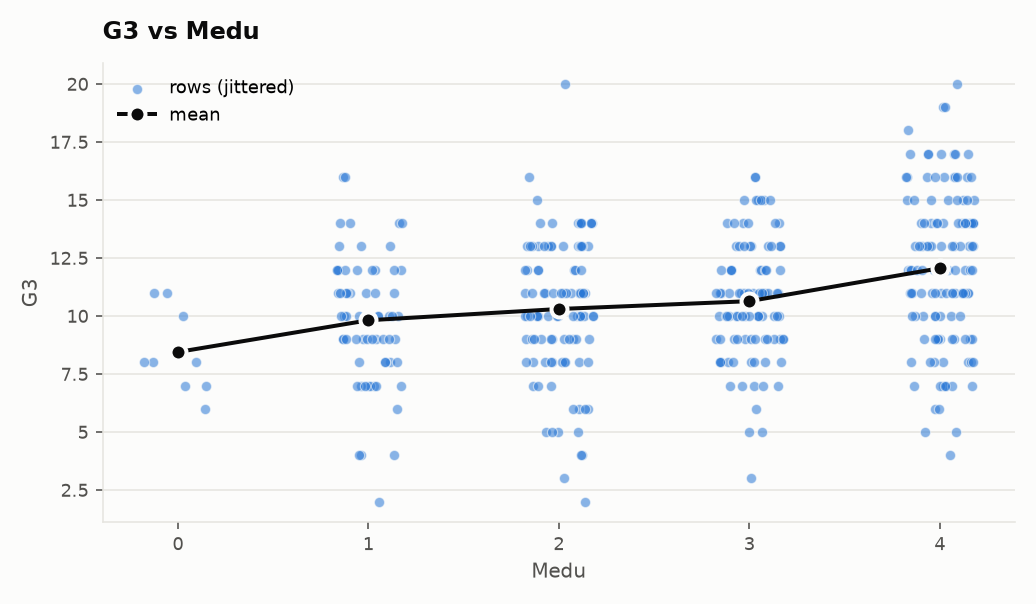

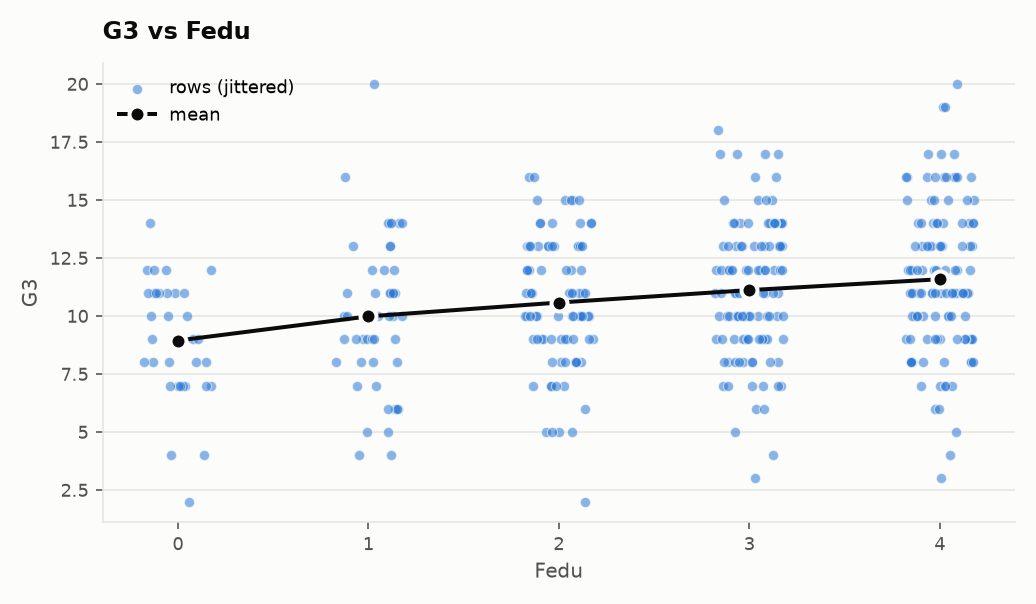

{0: 8.44, 1: 9.81, 2: 10.3, 3: 10.64, 4: 12.06}


In [5]:
ex1 = ask(agent, "Generate scatter plots showing the relationship between 'Medu' (mother's education level) and "
                 "'G3' (final grade), and between 'Fedu' (father's education level) and 'G3'.")
print_trace(ex1["messages"])
for path in charts(ex1):
    display(Image(path, width=440))
print(df.groupby("Medu")["G3"].mean().round(2).to_dict())  # check with plain pandas

**Exercise 2** — internet access at home vs average final grade.

Average G3 by internet - no: 10.55, yes: 10.95. Chart saved to charts/bar-internet-G3-mean.png.


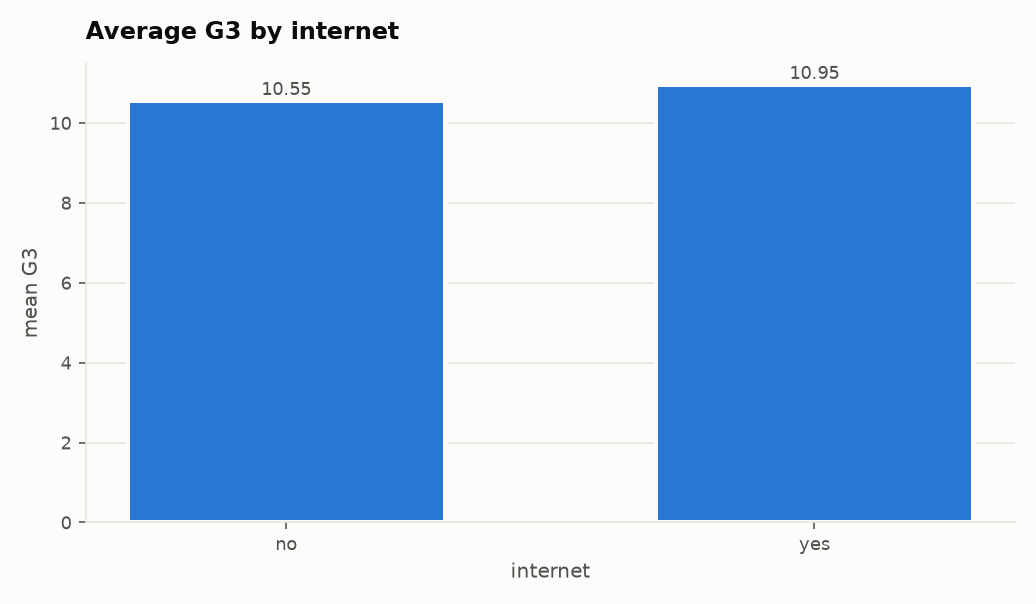

{'agg': 'mean', 'column': 'G3', 'by': 'internet', 'values': {'no': 10.549, 'yes': 10.951}, 'n': {'no': 133, 'yes': 267}}


In [6]:
ex2 = ask(agent, "Use bar plots to compare the average final grades ('G3') of students with internet access "
                 "at home versus those without ('internet' column).")
print(final_answer(ex2))
display(Image(charts(ex2)[0], width=440))
print(aggregate.invoke({"column": "G3", "by": "internet"}))  # the same numbers, no chart

**Exercise 3** — absences vs final grade, and *the code behind the chart*. In the lab you read the LLM's generated code from `intermediate_steps`; here every chart tool returns its equivalent code.

G3 vs absences: r = -0.093 (no clear relationship). Chart saved to charts/scatter-absences-G3.png.
import pandas as pd
import matplotlib.pyplot as plt

df = pd.read_csv('data/students.csv')
df.plot(kind='scatter', x='absences', y='G3')
plt.title('G3 vs absences')
plt.savefig('scatter-absences-G3.png')
print(df['absences'].corr(df['G3']))


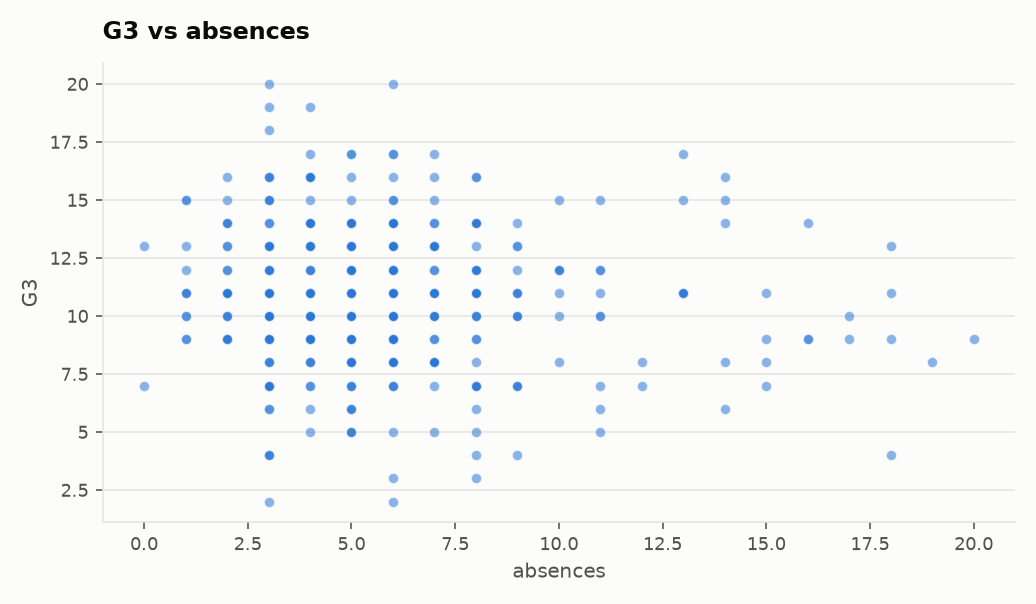

In [7]:
ex3 = ask(agent, "Plot a scatter plot showing the correlation between the number of absences ('absences') "
                 "and final grades ('G3') of students.")
print(final_answer(ex3))
chart = [c for c in tool_calls(ex3) if c["name"] == "make_chart"][0]
print(chart["result"]["code"])
display(Image(chart["result"]["path"], width=440))

## 5. Another dataset: online sales over time

Total revenue by month per category: peaks - Electronics 2025-11 (514,559), Fashion 2025-11 (109,668), Home 2025-12 (103,226). Chart saved to charts/line-month-revenue-category-sum.png.


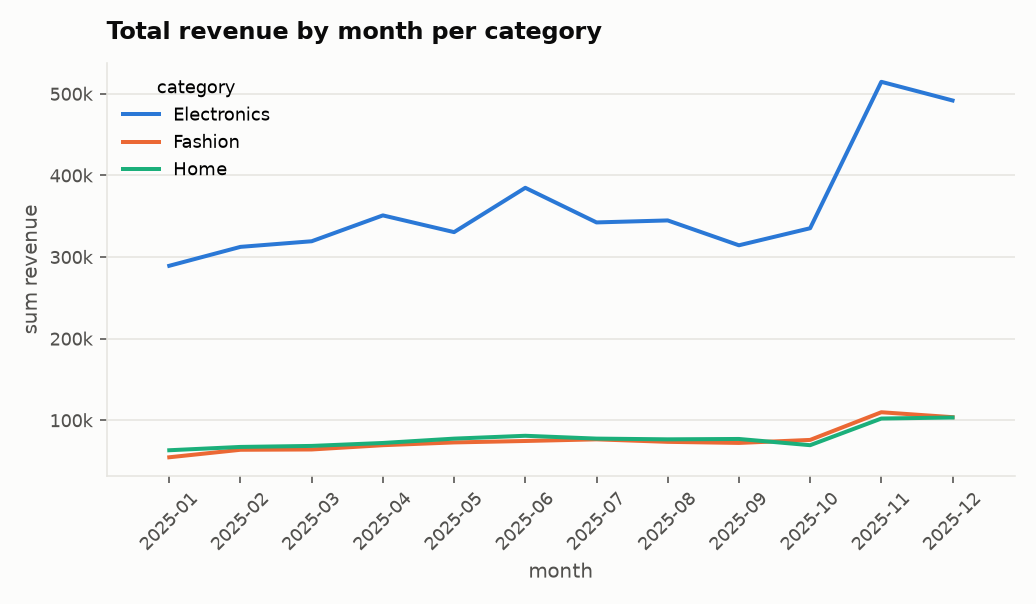

In [8]:
sales = ask(agent, "Plot total revenue by month per category")
print(final_answer(sales))
display(Image(charts(sales)[0], width=520))

## 6. Evaluate the agent: check the charts it chose, not the wording

In [9]:
expected = {("count", "sex", ""), ("scatter", "Medu", "G3"), ("scatter", "Fedu", "G3"), ("bar", "internet", "G3")}
first = ask(agent, LAB[0])
actual = {(c["args"]["kind"], c["args"].get("x", ""), c["args"].get("y", ""))
          for r in (first, ex1, ex2) for c in tool_calls(r) if c["name"] == "make_chart"}
for item in sorted(expected):
    print("✅" if item in actual else "❌", item)
print(f"\n{len(expected & actual)}/{len(expected)} checks passed")

✅ ('bar', 'internet', 'G3')
✅ ('count', 'sex', '')
✅ ('scatter', 'Fedu', 'G3')
✅ ('scatter', 'Medu', 'G3')

4/4 checks passed
